# 07 - Feature Selection

**Author:** Faizan NORAT

**Week 3 - Model Development and Experimentation**

This notebook investigates the impact of supervised
feature selection on the performance of our
TF-IDF logistic regression baseline.

We use the chi-square statistic to select informative
text features and compare different vocabulary sizes
in terms of classification performance and training time.

The test set is reserved for final evaluation.

In [6]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline

sys.path.append(os.path.join("..", "src"))

from evaluation import (
    LABELS_28,
    to_multi_hot,
    tune_thresholds,
    apply_thresholds,
    compute_metrics
)

SEED = 42

DATA_DIR = os.path.join("..", "data", "processed")
OUT_DIR = os.path.join("..", "results", "feature_selection")

os.makedirs(OUT_DIR, exist_ok=True)

In [7]:
df_train = pd.read_parquet(
    os.path.join(DATA_DIR, "train.parquet")
)

df_val = pd.read_parquet(
    os.path.join(DATA_DIR, "validation.parquet")
)

X_train = df_train["text"]
X_val = df_val["text"]

y_train = to_multi_hot(df_train["labels_28"], LABELS_28)
y_val = to_multi_hot(df_val["labels_28"], LABELS_28)

print("Training:", y_train.shape)
print("Validation:", y_val.shape)

assert y_train.shape == (43188, 28)
assert y_val.shape == (5377, 28)

Training: (43188, 28)
Validation: (5377, 28)


In [8]:
print("Training:", y_train.shape)
print("Validation:", y_val.shape)

print("Columns:", df_train.columns.tolist())

Training: (43188, 28)
Validation: (5377, 28)
Columns: ['id', 'text', 'text_raw', 'labels_28', 'labels_ekman', 'labels_sentiment']


## 1. Multi-label chi-square feature selection

The chi-square statistic measures the association
between a non-negative feature and a target label.

Since GoEmotions is multi-label, we compute chi-square
scores separately for each of the 28 binary targets.

Each feature receives the maximum score obtained
across all labels. This allows features associated
with a specific emotion to remain eligible for selection.

Feature selection is fitted exclusively on training data
inside the pipeline to prevent data leakage.

In [9]:
class MultiLabelChi2(BaseEstimator, TransformerMixin):

    def __init__(self, k=5000):
        self.k = k

    def fit(self, X, y):

        scores = []

        for i in range(y.shape[1]):
            label_scores, _ = chi2(X, y[:, i])
            scores.append(label_scores)

        scores = np.nan_to_num(
            np.array(scores),
            nan=0.0
        )

        self.scores_ = scores.max(axis=0)

        k = min(self.k, X.shape[1])

        self.indices_ = np.sort(
            np.argsort(self.scores_)[-k:]
        )

        return self

    def transform(self, X):
        return X[:, self.indices_]

In [10]:
def make_pipeline(k=None):

    steps = [
        ("tfidf", TfidfVectorizer(
            lowercase=False,
            token_pattern=r"(?u)\b\w+\b|[^\w\s]",
            ngram_range=(1, 1),
            min_df=2,
            sublinear_tf=True
        ))
    ]

    if k is not None:
        steps.append(("selection", MultiLabelChi2(k=k)))

    steps.append((
        "clf",
        OneVsRestClassifier(
            LogisticRegression(
                C=4,
                solver="liblinear",
                max_iter=1000
            )
        )
    ))

    return Pipeline(steps)


def crossfit_predict(y_true, proba):

    rng = np.random.RandomState(SEED)
    order = rng.permutation(len(y_true))

    half_a = order[:len(order) // 2]
    half_b = order[len(order) // 2:]

    y_pred = np.zeros_like(y_true)

    for tune_idx, apply_idx in [
        (half_a, half_b),
        (half_b, half_a)
    ]:

        thresholds = tune_thresholds(
            y_true[tune_idx],
            proba[tune_idx]
        )

        y_pred[apply_idx] = apply_thresholds(
            proba[apply_idx],
            thresholds
        )

    return y_pred

In [11]:
feature_sizes = [None, 10000, 5000, 2000, 1000]

rows = []

for k in feature_sizes:

    model = make_pipeline(k)

    start = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start

    proba = model.predict_proba(X_val)

    y_pred = crossfit_predict(y_val, proba)

    metrics = compute_metrics(y_val, y_pred)

    n_features = len(
        model.named_steps["tfidf"].vocabulary_
    )

    if k is not None:
        n_features = len(
            model.named_steps["selection"].indices_
        )

    rows.append({
        "configuration": "All" if k is None else str(k),
        "n_features": n_features,
        "training_time_s": training_time,
        **metrics
    })

    print(
        "Features:", n_features,
        "| Macro-F1:", round(metrics["macro_f1"], 4),
        "| Time:", round(training_time, 2), "s"
    )

feature_results = pd.DataFrame(rows)

feature_results.to_csv(
    os.path.join(OUT_DIR, "feature_selection_results.csv"),
    index=False
)

feature_results.round(4)

Features: 15265 | Macro-F1: 0.4771 | Time: 12.15 s
Features: 10000 | Macro-F1: 0.4775 | Time: 12.77 s
Features: 5000 | Macro-F1: 0.4825 | Time: 6.52 s
Features: 2000 | Macro-F1: 0.4794 | Time: 5.37 s
Features: 1000 | Macro-F1: 0.4736 | Time: 4.71 s


,configuration,n_features,training_time_s,macro_f1,micro_f1,weighted_f1,exact_match
0,All,15265,12.1515,0.4771,0.5211,0.5348,0.3084
1,10000,10000,12.7721,0.4775,0.5230,0.5369,0.3048
2,5000,5000,6.5177,0.4825,0.5358,0.5409,0.3426
3,2000,2000,5.3671,0.4794,0.5392,0.5435,0.3545
4,1000,1000,4.7086,0.4736,0.5296,0.5337,0.3522


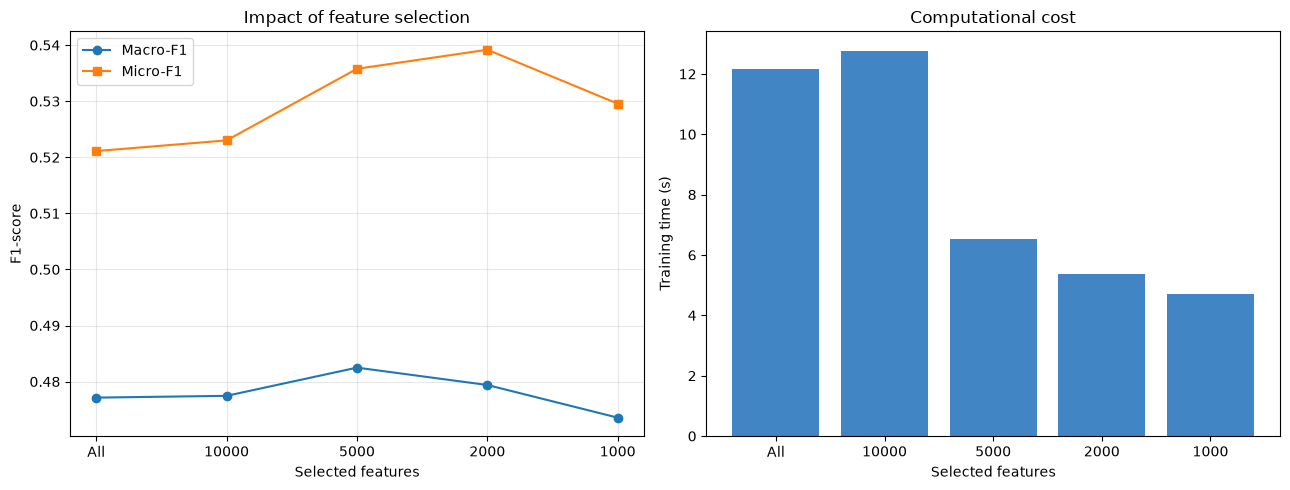

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    feature_results["configuration"],
    feature_results["macro_f1"],
    marker="o",
    label="Macro-F1"
)

axes[0].plot(
    feature_results["configuration"],
    feature_results["micro_f1"],
    marker="s",
    label="Micro-F1"
)

axes[0].set_xlabel("Selected features")
axes[0].set_ylabel("F1-score")
axes[0].set_title("Impact of feature selection")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(
    feature_results["configuration"],
    feature_results["training_time_s"],
    color="#4285C4"
)

axes[1].set_xlabel("Selected features")
axes[1].set_ylabel("Training time (s)")
axes[1].set_title("Computational cost")

plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "feature_selection_comparison.png"),
    dpi=150
)

plt.show()